# Detecția cu prag și curbele ROC

Laboratorul 6, DEPI

# 1. Obiectiv

Simularea transmisiei biților folosind două niveluri de tensiune și
zgomot aditiv, luarea deciziilor la receptor prin compararea cu un prag
și măsurarea detecțiilor și a alarmelor false. Alegerea unui prag pe
baza criteriului plauzibilității maxime și reprezentarea unei curbe ROC.

# 2. Aspecte teoretice

## 2.1 Decizii binare prin compararea cu un prag

Un emițător poate reprezenta fiecare bit printr-un nivel constant de
tensiune:

- bit 0: $s=0$ V; (sau o altă valoare)
- bit 1: $s=A$ V, unde $A>0$.

Semnalul este afectat de zgomot aditiv. Receptorul ia câte un eșantion
pentru fiecare bit transmis, pentru a lua o decizie. Tensiunea
recepționată este:

<span id="eq-received-voltage">$$
r=s+n,
 \qquad(1)$$</span>

unde $n$ este zgomotul aditiv. Cele două ipoteze descriu ce s-a
transmis:

- $H_0$: s-a transmis bitul 0 ($s=0$ V);
- $H_1$: s-a transmis bitul 1 ($s=A$ V).

Receptorul nu cunoaște bitul transmis. Receptorul compară $r$ cu un prag
$T$ și ia una dintre cele două decizii:

<span id="eq-threshold-rule">$$
D_1\text{ (decide bit 1) dacă }r>T;\qquad
D_0\text{ (decide bit 0) dacă }r\le T.
 \qquad(2)$$</span>

Ipotezele $H_0$ și $H_1$ reprezintă bitul transmis în realitate.
Deciziile $D_0$ și $D_1$ reprezintă decizia receptorului. Zgomotul poate
provoca o decizie greșită.

## 2.2 Cele patru scenarii posibile

- **Rejecție corectă** ($D_0 \mid H_0$): receptorul decide 0 ($D_0$)
  când s-a transmis bitul 0 ($H_0$).
- **Alarmă falsă** ($D_1 \mid H_0$): receptorul decide 1 ($D_1$) când
  s-a transmis bitul 0 ($H_0$).
- **Pierdere** ($D_0 \mid H_1$): receptorul decide 0 ($D_0$) când s-a
  transmis bitul 1 ($H_1$).
- **Detecție corectă** ($D_1 \mid H_1$): receptorul decide 1 ($D_1$)
  când s-a transmis bitul 1 ($H_1$).

Putem calcula probabilitățile (condiționate) ale acestor patru
rezultate, pe baza distribuțiilor $w(r\mid H_0)$ și $w(r\mid H_1)$ din
<a href="#fig-conditional-probabilities"
class="quarto-xref">Figure 1</a>. Știm să calculăm astfel de
probabilități.

- Probabilitatea de rejecție corectă: $P_{\mathrm{CR}}=P(D_0\mid H_0)$.
- Probabilitatea de alarmă falsă: $P_{\mathrm{FA}}=P(D_1\mid H_0)$.
- Probabilitatea de pierdere: $P_{\mathrm{M}}=P(D_0\mid H_1)$.
- Probabilitatea de detecție corectă: $P_{\mathrm{D}}=P(D_1\mid H_1)$.

<figure id="fig-conditional-probabilities">
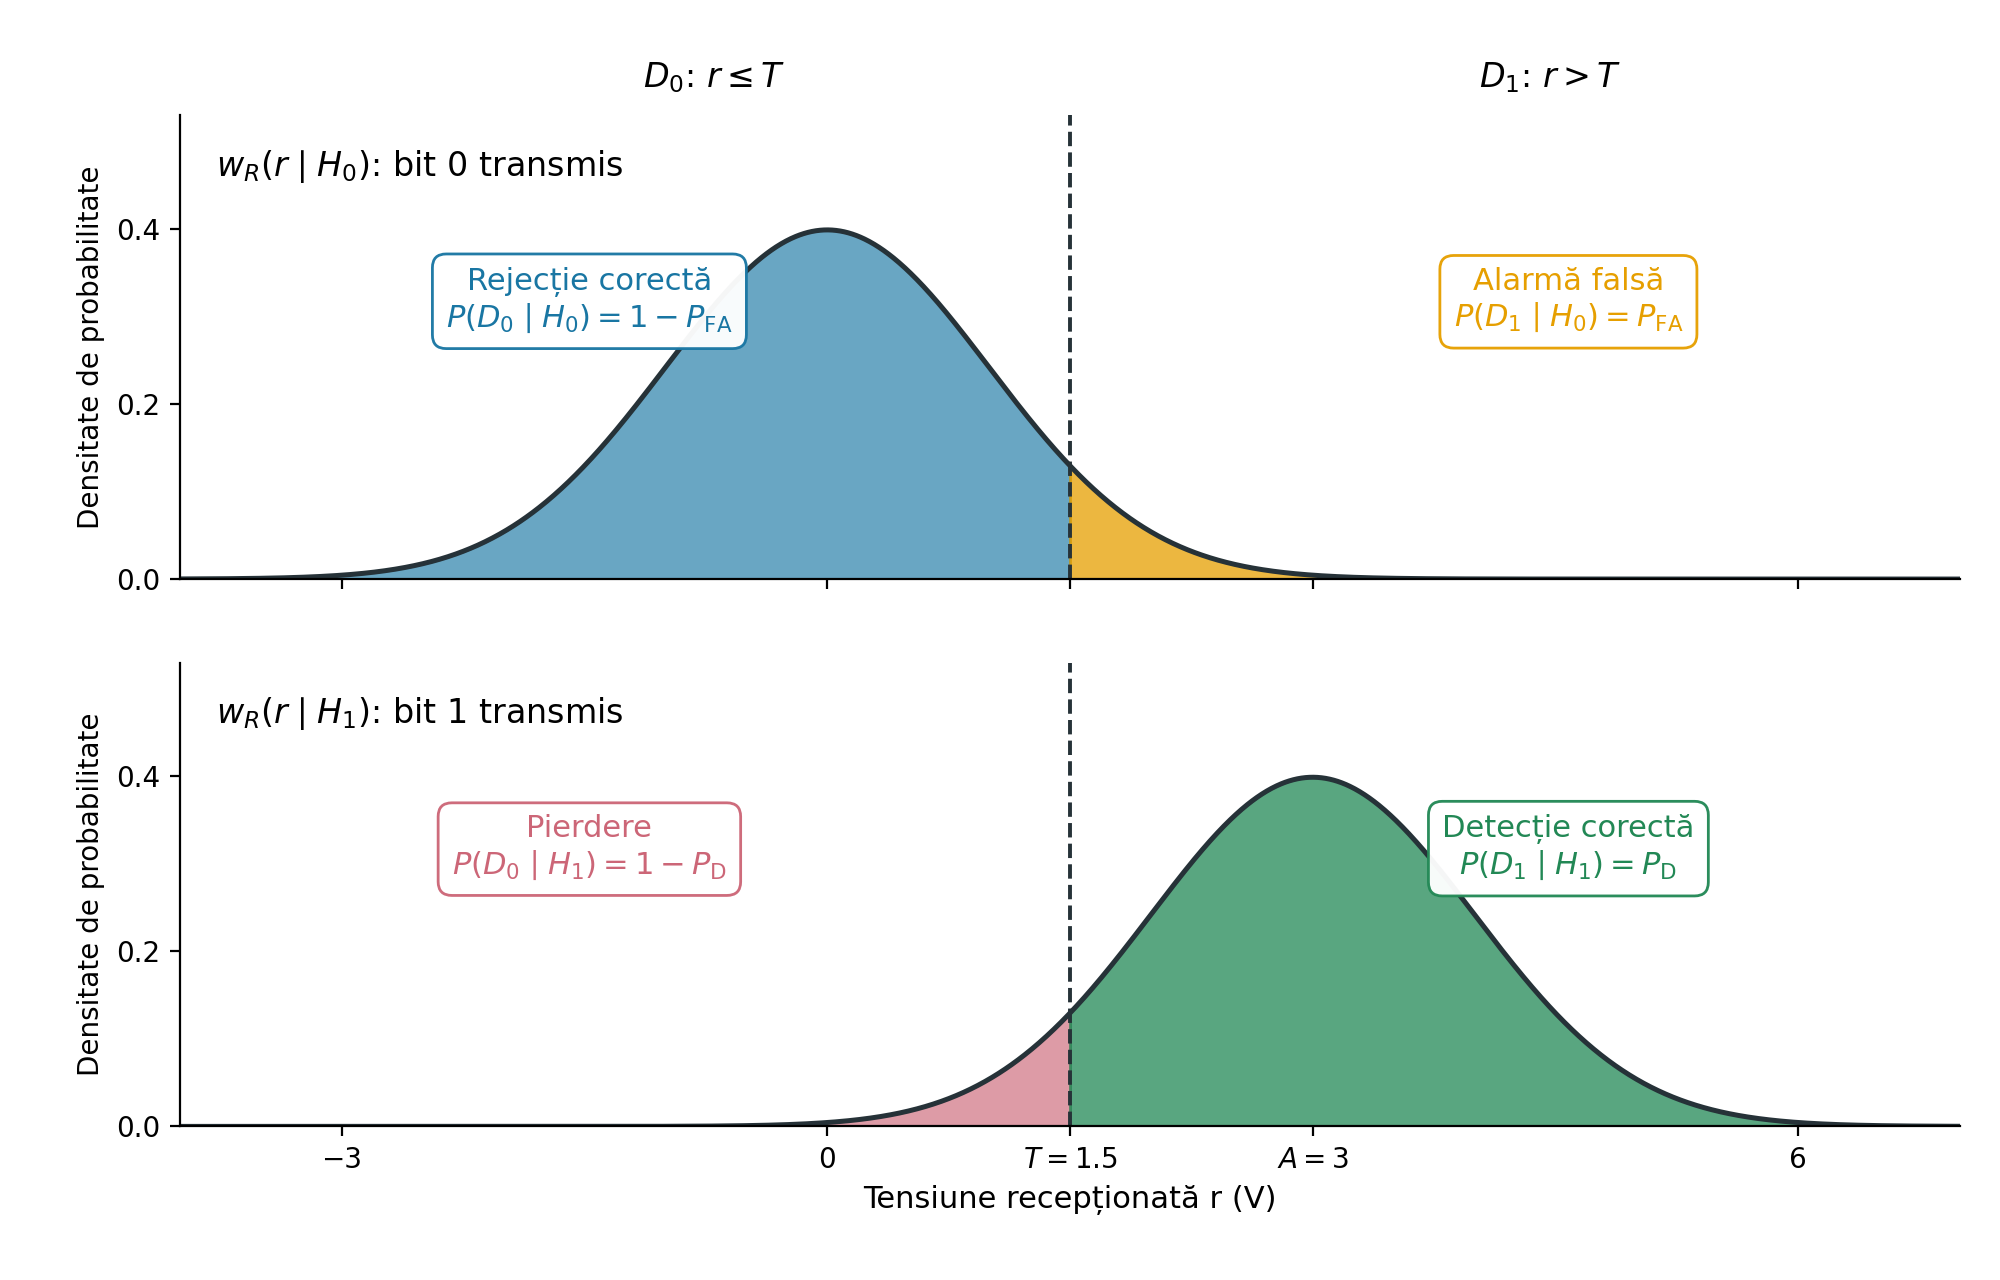
<figcaption>Figure 1: Cele patru probabilități condiționate sunt ariile
de sub cele două distribuții condiționate. Valoarea de prag împarte
fiecare densitate în două, corespunzător deciziilor <span
class="math inline"><em>D</em><sub>0</sub></span> (stânga) și <span
class="math inline"><em>D</em><sub>1</sub></span> (dreapta). Exemplu
pentru zgomot gaussian cu deviația standard de 1 V și <span
class="math inline"><em>A</em> = 3</span> V.</figcaption>
</figure>

În practică, aceste valori pot fi estimate dintr-un număr finit de
observații, prin numărare.

<span id="eq-estimated-probabilities">$$
\widehat{P}_{\mathrm{FA}} = \frac{\text{numărul de alarme false}}{\text{numărul de biți 0 transmiși}}
\qquad
\widehat{P}_{\mathrm{D}} = \frac{\text{numărul de detecții corecte}}{\text{numărul de biți 1 transmiși}}.
 \qquad(3)$$</span>

## 2.3 Criteriul plauzibilității maxime (Maximum Likelihood, ML)

Cum alegem valoarea pragului $T$, adică cum luăm o decizie pe baza unei
tensiuni recepționate $r$?

**Criteriul plauzibilității maxime (Maximum Likelihood, ML)** alege
ipoteza pentru care funcția densitate de probabilitate are valoarea mai
mare în dreptul valorii recepționate $r$:

- se ia decizia $D_1$ dacă $w_R(r\mid H_1)>w_R(r\mid H_0)$
- se ia decizia $D_0$ dacă $w_R(r\mid H_1)\le w_R(r\mid H_0)$.

În cazul nostru, aceasta înseamnă alegerea pragului $T$ la intersecția
celor două densități, aflată la mijloc, după cum se vede în
<a href="#fig-conditional-probabilities"
class="quarto-xref">Figure 1</a>.

$$
T_{\mathrm{ML}} = \frac{0 + A}{2}
$$

## 2.4 Curba ROC

În general, alegerea unui prag $T$ presupune un compromis între alarmele
false și detecțiile corecte.

**Caracteristica de operare a receptorului (Receiver Operating
Characteristic, ROC)** este o reprezentare grafică obținută prin
variația lui $T$ și reprezentarea celor două mărimi:

- pe axa orizontală: $P_{\mathrm{FA}}$;
- pe axa verticală: $P_{\mathrm{D}}$.

Fiecare valoare a pragului corespunde unui punct de pe curbă.
Proiectantul alege pragul în funcție de cerințele aplicației.

Curba ROC ne indică cât de bine pot fi separate cele două situații, în
general.

<figure id="fig-typical-roc">
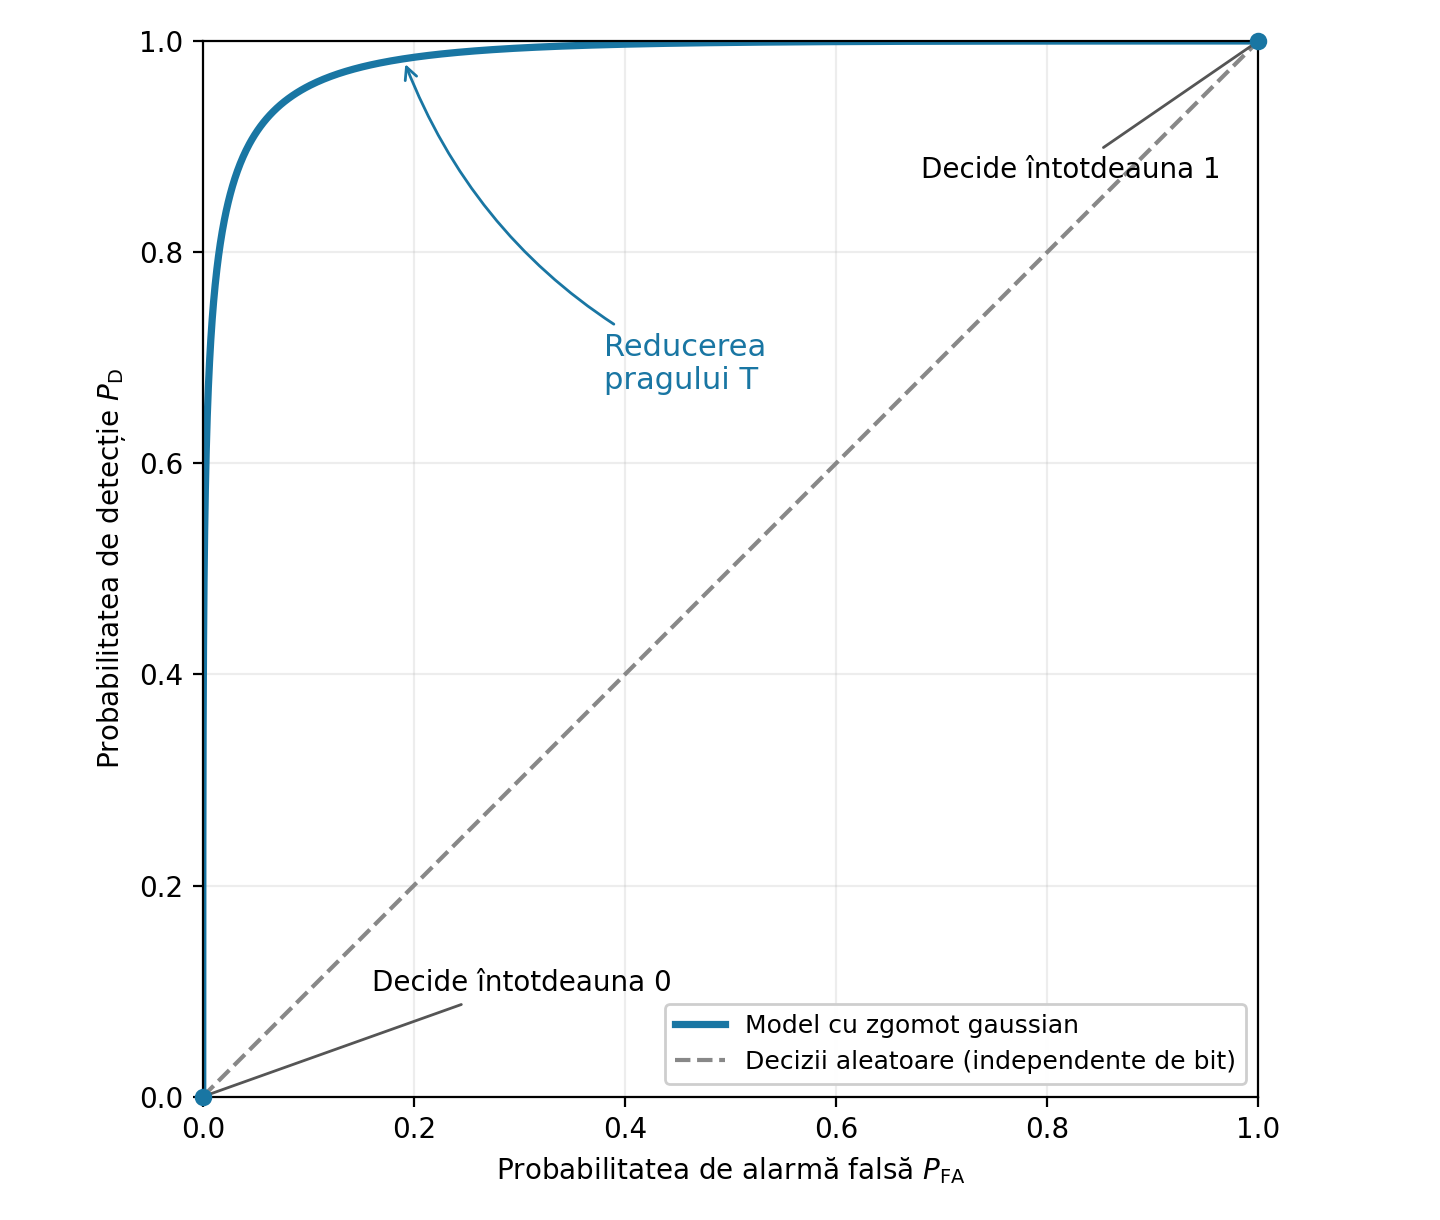
<figcaption>Figure 2: O curbă ROC tipică pentru modelul din laborator
(<span class="math inline"><em>A</em> = 3</span> V, zgomot normal,
deviația standard de 1 V). Reducerea pragului deplasează punctul de
funcționare de la <span class="math inline">(0, 0)</span> către <span
class="math inline">(1, 1)</span>. Diagonala întreruptă reprezintă
decizii aleatoare, independente de bitul transmis; curbele mai apropiate
de colțul din stânga sus indică o separare mai bună.</figcaption>
</figure>

## 2.5 Matlab

### Generarea unor biți aleatori cu probabilități fixe

Folosiți `rand(1,N)` pentru a genera `N` valori uniforme între 0 și 1.
Compararea fiecărei valori cu 0.5 produce biți aleatori cu probabilități
egale, $50\%$ pentru 0 și $50\%$ pentru 1:

``` matlab
N = 20000;
bits = rand(1,N) > 0.5;
```

Pentru a modifica proporțiile, adaptați pragul de comparație. De
exemplu, pentru a obține aproximativ **30% zerouri și 70% biți de 1**:

``` matlab
bits = rand(1,N) > 0.3;
```

Valorile mai mici sau egale cu 0.3 devin 0; valorile mai mari decât 0.3
devin 1. Deoarece `rand()` are distribuție uniformă, probabilitățile
sunt $P(0)=0.3$ și $P(1)=0.7$.

Mai general, `rand(1,N) > p0` produce zerouri cu probabilitatea `p0` și
biți de 1 cu probabilitatea `1-p0`.

### Tensiuni transmise și recepționate

Înmulțiți vectorul de biți cu $A$, sau folosiți metode similare, pentru
a obține tensiunile transmise.

Folosiți `randn()`, ca în Laboratorul 3, pentru a genera zgomot gaussian
independent și adăugați-l la tensiunile transmise pentru a obține
vectorul recepționat `r`.

Putem separa eșantioanele recepționate în funcție de biții transmiși
folosind indexarea logică.

``` matlab
r0 = r(bits == 0);
r1 = r(bits == 1);
```

Reamintire: `==` testează egalitatea element cu element, iar `=`
atribuie o valoare unei variabile.

### Variația pragului pentru curba ROC

Pentru a varia valoarea de prag, creați un vector precum
`thresholds = -4:0.05:7`. Prealocați vectorii de rezultate cu
`zeros(size(thresholds))`, apoi folosiți o buclă `for` pentru a completa
câte un element pentru fiecare prag. Reprezentați curba ROC cu
`plot(pFA,pD)`.

## 2.6 Sinteză: funcții și notații pe care trebuie să le cunoașteți

| Semnătură sau notație | Exemplu | Descriere |
|------------------------|------------------------|------------------------|
| `rand(1,N) > p0` | `bits = rand(1,N) > 0.3` | Biți aleatori: probabilitatea `p0` pentru 0 și `1-p0` pentru 1 |
| `A*bits` | `s = 3*bits` | Transformarea biților în nivelurile de tensiune 0 și $A$ |
| `r(bits == 0)` | `r0 = r(bits == 0)` | Selectarea eșantioanelor recepționate pentru care bitul transmis a fost 0 |
| `mu + sigma*randn(1,N)` | `3 + randn(1,10000)` | Valori normale cu media `mu` și deviația standard `sigma` |
| `r > T` | `decision = r > 1.5` | Decizii logice: 1 pentru $D_1$, 0 pentru $D_0$ |
| `sum(condition)` | `sum(r0 > T)` | Numărarea observațiilor care îndeplinesc o condiție |
| `numel(x)` | `numel(r0)` | Numărul de elemente dintr-un vector |
| `hold on`, `hold off`, `legend(...)` | `legend('Bit 0 transmis','Bit 1 transmis')` | Suprapunerea graficelor și identificarea lor |
| `a:step:b` | `-4:0.05:7` | Praguri candidate cu pas fix |
| `zeros(size(v))` | `pFA = zeros(size(thresholds))` | Prealocarea unui vector cu aceleași dimensiuni ca `v` |
| `for k = 1:numel(v)` | `T = thresholds(k)` în interiorul buclei | Parcurgerea fiecărui prag după indice |
| `plot(x,y)` | `plot(pFA,pD)` | Reprezentarea probabilității de detecție în funcție de probabilitatea de alarmă falsă |

# 3. Exercițiu teoretic

Un emițător transmite bitul 0 ca 0 V și bitul 1 ca 3 V. Eșantionul
recepționat este $r=s+n$, unde zgomotul are distribuția normală
$\mathcal{N}(0,1)$, cu tensiunile exprimate în volți. Receptorul decide
$D_1$ dacă $r>T$, și $D_0$ în caz contrar.

1.  Calculați probabilitățile teoretice de alarmă falsă și de detecție
    corectă:

    1.  Desenați distribuția lui $r$ pentru fiecare ipoteză, $w(r|H_0)$
        și $w(r|H_1)$.

    2.  Care este valoarea lui $T$ pentru regula de decizie a
        plauzibilității maxime (ML)?

    3.  Calculați probabilitatea de alarmă falsă $P_{\mathrm{FA}}$ și
        probabilitatea de detecție $P_{\mathrm{D}}$ pentru pragul ML.

# 4. Exerciții Matlab

Scrieți comenzile într-un script sau într-un live script.

1.  Simulați transmisia folosind două niveluri de tensiune:

    Folosiți $A=3$ V. Canalul adaugă zgomot gaussian independent, cu
    media 0 V și deviația standard de 1 V, la fiecare tensiune
    transmisă. Astfel, eșantioanele recepționate au distribuția
    $\mathcal{N}(0,1)$ pentru $H_0$ și $\mathcal{N}(3,1)$ pentru $H_1$,
    cu tensiunile exprimate în volți. Fiecare eșantion conduce la o
    decizie asupra unui bit.

    1.  Generați un vector linie `bits` cu 20000 de biți aleatori 0 și
        1, cu probabilități egale. Folosiți `rand()` și comparați
        valorile cu un prag potrivit.

    2.  Transformați `bits` într-un vector `s` de tensiuni transmise,
        folosind 0 V pentru bitul 0 și 3 V pentru bitul 1.

    3.  Generați un vector de zgomot de aceeași dimensiune, cu
        distribuția normală $\mathcal{N}(0,1)$, și creați vectorul
        recepționat `r = s + n`.

    4.  Rulați codul de mai jos pentru a estima cele două densități
        condiționate. Poate un prag să separe corect toate eșantioanele
        recepționate?

        ``` matlab
        % Selectarea eșantioanelor recepționate după bitul transmis
        r0 = r(bits == 0);  % Ce face această linie?
        r1 = r(bits == 1);  % Ce face această linie?

        % Aceleași limite ale intervalelor pentru ambele histograme
        edges = -4:0.25:7;
        figure
        histogram(r0, edges, 'Normalization', 'pdf', ...
            'FaceColor', [0 0.45 0.74], 'FaceAlpha', 0.5)
        hold on
        histogram(r1, edges, 'Normalization', 'pdf', ...
            'FaceColor', [0.85 0.33 0.10], 'FaceAlpha', 0.5)
        hold off
        xlabel('Tensiune recepționată (V)')
        ylabel('Densitate de probabilitate estimată')
        legend('Bit 0 transmis', 'Bit 1 transmis')
        ```

    5.  Alegeți din histograme un prag $T$ potrivit pentru a separa cele
        două distribuții. Ce se întâmplă cu alarmele false și pierderile
        când pragul crește? Dar când scade?

2.  Evaluați praguri individuale:

    1.  Setați `T = 1.5`. Calculați vectorul deciziilor `d` comparând
        valorile din `r` cu pragul. Fiecare element din `d` trebuie să
        fie 1 ($D_1$) dacă tensiunea recepționată este mai mare decât
        `T`, și 0 ($D_0$) în caz contrar. Vectorii `bits`, `r` și `d`
        trebuie să aibă aceeași dimensiune.

    2.  Comparați `d` cu vectorul transmis `bits` și numărați cele patru
        rezultate posibile:

        - rejecții corecte: bitul transmis este 0 și decizia este 0;
        - alarme false: bitul transmis este 0, dar decizia este 1;
        - pierderi: bitul transmis este 1, dar decizia este 0.
        - detecții corecte: bitul transmis este 1 și decizia este 1;

        Folosiți `==` pentru a testa egalitatea, `&` pentru a combina
        două condiții logice element cu element și `sum()` pentru a
        număra pozițiile care îndeplinesc ambele condiții. Puneți
        fiecare comparație între paranteze.

    3.  Numărați biții 0 și 1 transmiși și salvați numerele în `N0` și
        `N1`. Verificați că alarmele false plus rejecțiile corecte dau
        `N0`, iar detecțiile corecte plus pierderile dau `N1`.

    4.  Estimați probabilitatea de alarmă falsă `pFA` împărțind numărul
        alarmelor false la `N0`. Estimați `pD` împărțind numărul
        detecțiilor corecte la `N1`, iar probabilitatea de pierdere
        împărțind numărul pierderilor la `N1`. Verificați că
        probabilitățile de detecție și de pierdere au suma 1.

        Pentru `T = 1.5`, comparați `pFA` și `pD` cu rezultatele
        teoretice din [exercițiul teoretic](#sec-theoretical-exercise).
        De ce estimările nu sunt exact egale cu valorile teoretice?

    5.  Calculați numărul total de erori ca suma alarmelor false și a
        pierderilor. Verificați-l numărând pozițiile în care `d` diferă
        de `bits`, folosind `~=` (diferit).

    6.  Repetați pentru `T = 1` și `T = 2`, folosind aceiași vectori
        `bits` și `r`. Notați rezultatele într-un tabel cu câte un rând
        pentru fiecare prag și coloane pentru `T`, `pFA`, `pD` și
        numărul total de erori. Comparați cu predicția de la Exercițiul
        1.

3.  (Optional) Reprezentați curba ROC:

    1.  Creați vectorul `thresholds` cu praguri candidate de la -4 la 7,
        cu pasul 0.05.

    2.  Completați șablonul de mai jos pentru a calcula `pFA` și `pD`
        pentru fiecare prag. Înlocuiți fiecare `...` cu expresia
        potrivită, folosind metoda de numărare din Exercițiul 2. Nu
        generați zgomot nou în interiorul buclei.

        ``` matlab
        pFA = zeros(size(thresholds));
        pD = zeros(size(thresholds));

        for k = 1:numel(thresholds)
            T = thresholds(k);

            % Calcularea deciziilor pentru eșantioanele recepționate
            d = ...;

            % Compararea deciziilor cu biții transmiși și numărarea rezultatelor
            falseAlarms = ...;
            correctDetections = ...;

            % Împărțirea la numărul de eșantioane pentru bitul transmis corespunzător
            pFA(k) = ...;
            pD(k) = ...;
        end
        ```

    3.  Reprezentați vectorul `pD` în funcție de `pFA`.

# 5. Întrebări finale

1.  Dacă toate tensiunile recepționate cresc cu 10 V, cum trebuie
    modificat pragul pentru a păstra toate deciziile neschimbate? S-ar
    modifica curba ROC?
2.  Poate un detector să nu producă nicio alarmă falsă în 10000 de
    eșantioane simulate pentru bitul 0 transmis, deși probabilitatea sa
    reală de alarmă falsă este pozitivă?
3.  Un receptor decide întotdeauna $D_0$ (bit 0). Care sunt
    probabilitățile sale de detecție și de alarmă falsă? Unde se află
    punctul său pe curba ROC? Dar dacă decide întotdeauna $D_1$?